In [1]:
#necessary libraries
import pandas as pd
import collections 
import numpy as np 
import matplotlib.pyplot as plt 
%matplotlib inline
import seaborn as sns 
from sklearn.linear_model import LogisticRegression 
from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings("ignore")


In [13]:
df = pd.read_csv(r"C:\Users\Hiba\Downloads\archive (3)\Pakistan Largest Ecommerce Dataset.csv")

C:\Users\Hiba\AppData\Local\Temp\ipykernel_13040\800808859.py:1: DtypeWarning: Columns (1,2,3,7,8,9,11,12,13,14,17,18,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\Hiba\Downloads\archive (3)\Pakistan Largest Ecommerce Dataset.csv")


In [15]:
df.shape

(1048575, 26)

In [16]:
df.columns

Index(['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered',
       'grand_total', 'increment_id', 'category_name_1',
       'sales_commission_code', 'discount_amount', 'payment_method',
       'Working Date', 'BI Status', ' MV ', 'Year', 'Month', 'Customer Since',
       'M-Y', 'FY', 'Customer ID', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23',
       'Unnamed: 24', 'Unnamed: 25'],
      dtype='object')

In [17]:
df.head

<bound method NDFrame.head of           item_id          status created_at  \
0        211131.0        complete   7/1/2016   
1        211133.0        canceled   7/1/2016   
2        211134.0        canceled   7/1/2016   
3        211135.0        complete   7/1/2016   
4        211136.0  order_refunded   7/1/2016   
...           ...             ...        ...   
1048570       NaN             NaN        NaN   
1048571       NaN             NaN        NaN   
1048572       NaN             NaN        NaN   
1048573       NaN             NaN        NaN   
1048574       NaN             NaN        NaN   

                                                       sku   price  \
0                                        kreations_YI 06-L  1950.0   
1        kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...   240.0   
2                                       Ego_UP0017-999-MR0  2450.0   
3                                           kcc_krone deal   360.0   
4                                          

In [18]:
df.describe()

,item_id,price,qty_ordered,grand_total,discount_amount,Year,Month,Customer ID,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
count,584524.000000,5.845240e+05,584524.000000,5.845240e+05,584524.000000,584524.000000,584524.000000,584513.000000,0.0,0.0,0.0,0.0,0.0
mean,565667.074218,6.348748e+03,1.296388,8.530619e+03,499.492775,2017.044115,7.167654,45790.511965,NaN,NaN,NaN,NaN,NaN
std,200121.173648,1.494927e+04,3.996061,6.132081e+04,1506.943046,0.707355,3.486305,34414.962389,NaN,NaN,NaN,NaN,NaN
min,211131.000000,0.000000e+00,1.000000,-1.594000e+03,-599.500000,2016.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN
25%,395000.750000,3.600000e+02,1.000000,9.450000e+02,0.000000,2017.000000,4.000000,13516.000000,NaN,NaN,NaN,NaN,NaN
50%,568424.500000,8.990000e+02,1.000000,1.960400e+03,0.000000,2017.000000,7.000000,42856.000000,NaN,NaN,NaN,NaN,NaN
75%,739106.250000,4.070000e+03,1.000000,6.999000e+03,160.500000,2018.000000,11.000000,73536.000000,NaN,NaN,NaN,NaN,NaN
max,905208.000000,1.012626e+06,1000.000000,1.788800e+07,90300.000000,2018.000000,12.000000,115326.000000,NaN,NaN,NaN,NaN,NaN


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 26 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   item_id                584524 non-null  float64
 1   status                 584509 non-null  object 
 2   created_at             584524 non-null  object 
 3   sku                    584504 non-null  object 
 4   price                  584524 non-null  float64
 5   qty_ordered            584524 non-null  float64
 6   grand_total            584524 non-null  float64
 7   increment_id           584524 non-null  object 
 8   category_name_1        584360 non-null  object 
 9   sales_commission_code  447346 non-null  object 
 10  discount_amount        584524 non-null  float64
 11  payment_method         584524 non-null  object 
 12  Working Date           584524 non-null  object 
 13  BI Status              584524 non-null  object 
 14   MV                    584524 non-

In [67]:
#splitting the dataset into numerical and categorical columns
import pandas as pd

df = pd.read_csv(r"C:\Users\Hiba\Downloads\archive (3)\Pakistan Largest Ecommerce Dataset.csv",low_memory = False)

# Extract numerical columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
numerical_df = df[numerical_columns]

# Extract categorical columns
categorical_columns = df.select_dtypes(include=['object', 'category']).columns
categorical_df = df[categorical_columns]

In [34]:
for col in categorical_df:
    print(f"Unique values in {col}: {df[col].unique()}")

Unique values in status: ['complete' 'canceled' 'order_refunded' 'received' 'refund' 'closed'
 'fraud' 'holded' 'exchange' 'pending_paypal' 'paid' '\\N' 'cod' 'pending'
 nan 'processing' 'payment_review']
Unique values in created_at: ['7/1/2016' '7/2/2016' '7/3/2016' '7/4/2016' '7/5/2016' '7/6/2016'
 '7/7/2016' '7/8/2016' '7/9/2016' '7/10/2016' '7/11/2016' '7/12/2016'
 '7/13/2016' '7/14/2016' '7/15/2016' '7/16/2016' '7/17/2016' '7/18/2016'
 '7/19/2016' '7/20/2016' '7/21/2016' '7/22/2016' '7/23/2016' '7/24/2016'
 '7/25/2016' '7/26/2016' '7/27/2016' '7/28/2016' '7/29/2016' '7/30/2016'
 '7/31/2016' '8/1/2016' '8/2/2016' '8/3/2016' '8/4/2016' '8/5/2016'
 '8/6/2016' '8/7/2016' '8/8/2016' '8/9/2016' '8/10/2016' '8/11/2016'
 '8/12/2016' '8/13/2016' '8/14/2016' '8/15/2016' '8/16/2016' '8/17/2016'
 '8/18/2016' '8/19/2016' '8/20/2016' '8/21/2016' '8/22/2016' '8/23/2016'
 '8/24/2016' '8/25/2016' '8/26/2016' '8/27/2016' '8/28/2016' '8/29/2016'
 '8/30/2016' '8/31/2016' '9/1/2016' '9/2/2016' '9/3/20

In [38]:
numerical_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 13 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   item_id          584524 non-null  float64
 1   price            584524 non-null  float64
 2   qty_ordered      584524 non-null  float64
 3   grand_total      584524 non-null  float64
 4   discount_amount  584524 non-null  float64
 5   Year             584524 non-null  float64
 6   Month            584524 non-null  float64
 7   Customer ID      584513 non-null  float64
 8   Unnamed: 21      0 non-null       float64
 9   Unnamed: 22      0 non-null       float64
 10  Unnamed: 23      0 non-null       float64
 11  Unnamed: 24      0 non-null       float64
 12  Unnamed: 25      0 non-null       float64
dtypes: float64(13)
memory usage: 104.0 MB


In [39]:
categorical_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 13 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   status                 584509 non-null  object
 1   created_at             584524 non-null  object
 2   sku                    584504 non-null  object
 3   increment_id           584524 non-null  object
 4   category_name_1        584360 non-null  object
 5   sales_commission_code  447346 non-null  object
 6   payment_method         584524 non-null  object
 7   Working Date           584524 non-null  object
 8   BI Status              584524 non-null  object
 9    MV                    584524 non-null  object
 10  Customer Since         584513 non-null  object
 11  M-Y                    584524 non-null  object
 12  FY                     584524 non-null  object
dtypes: object(13)
memory usage: 104.0+ MB


In [20]:
import numpy as np

# Inspect missing values in the dataset
print(df.isnull().values.sum())

# Replace the ' 's with NaN
df = df.replace(" ",np.NaN)

# Count the number of NaNs in the dataset to verify
print(df.isnull().values.sum())

15125345
15125345


In [21]:
df_copy = df.copy()

C:\Users\Hiba\AppData\Local\Temp\ipykernel_13040\806512888.py:1: DtypeWarning: Columns (1,2,3,7,8,9,11,12,13,14,17,18,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\Hiba\Downloads\archive (3)\Pakistan Largest Ecommerce Dataset.csv")
C:\Users\Hiba\anaconda\Lib\site-packages\matplotlib\axes\_axes.py:6834: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
C:\Users\Hiba\anaconda\Lib\site-packages\matplotlib\axes\_axes.py:6835: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))


ValueError: autodetected range of [nan, nan] is not finite

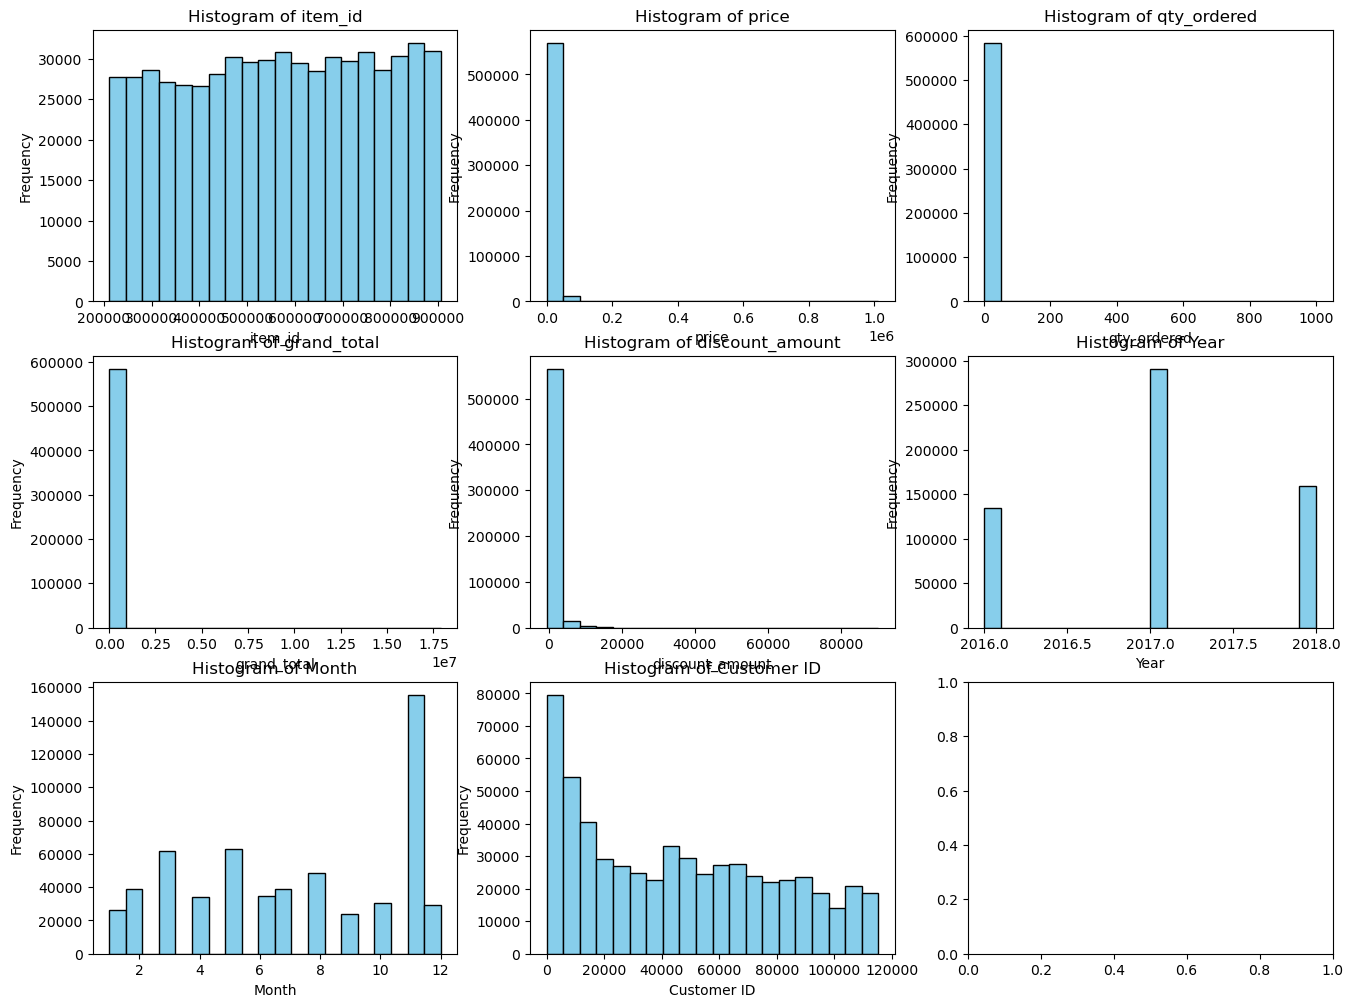

In [23]:
df = pd.read_csv(r"C:\Users\Hiba\Downloads\archive (3)\Pakistan Largest Ecommerce Dataset.csv")

# Select only the numerical columns (if there are non-numerical columns in the DataFrame)
numerical_columns = df.select_dtypes(include=['float64', 'int64']).columns

# Create histograms for each numerical column
plt.figure(figsize=(16, 12))  
for i, column in enumerate(numerical_columns, 1):
    plt.subplot(3, 3, i)  # Adjust the number of rows/columns as needed (3x3 grid for 8 histograms)
    plt.hist(df[column], bins=20, color='skyblue', edgecolor='black')
    plt.title(f'Histogram of {column}', fontsize=12)
    plt.xlabel(column, fontsize=10)
    plt.ylabel('Frequency', fontsize=10)

plt.tight_layout()
plt.show()

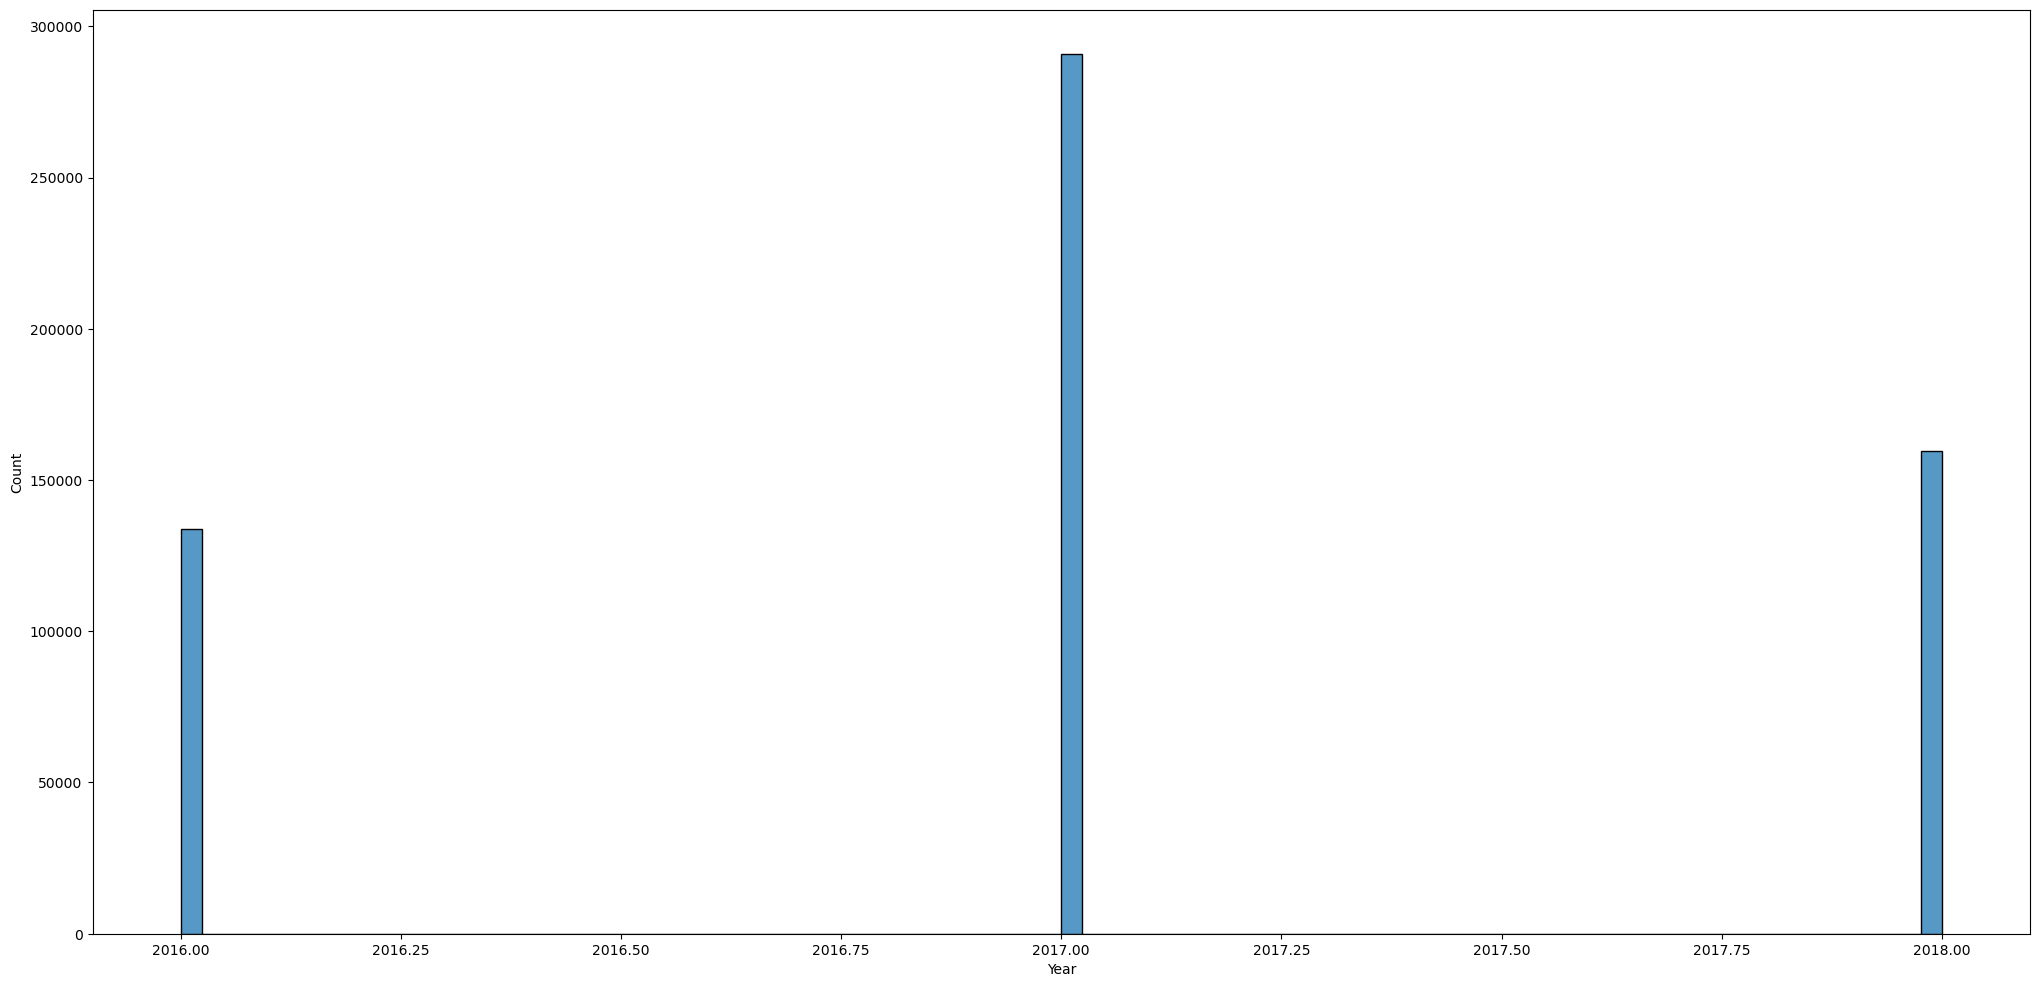

In [54]:
#histogram of individual column using seaborn
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(25, 12))
sns.histplot(data = df_copy,x ='Year')
plt.show()

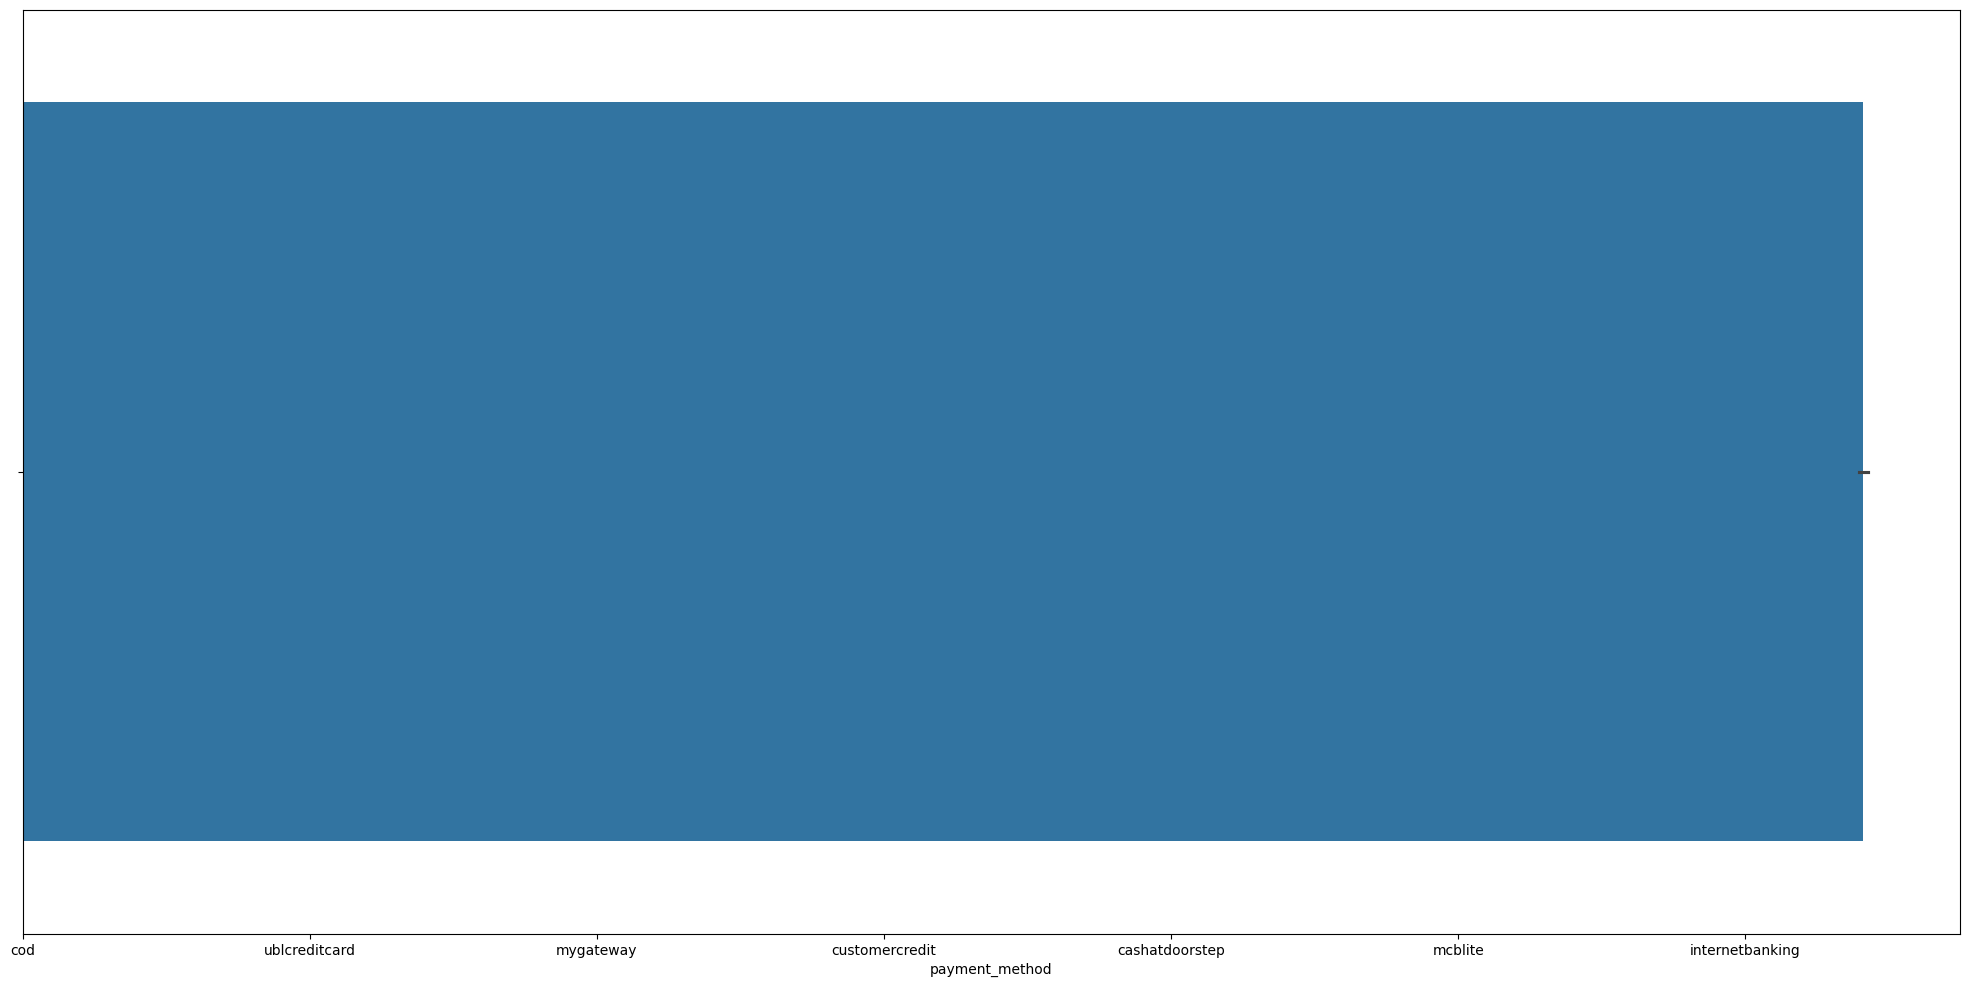

In [52]:
plt.figure(figsize=(25, 12))
sns.barplot(data = df_copy,x ='payment_method')
plt.show()

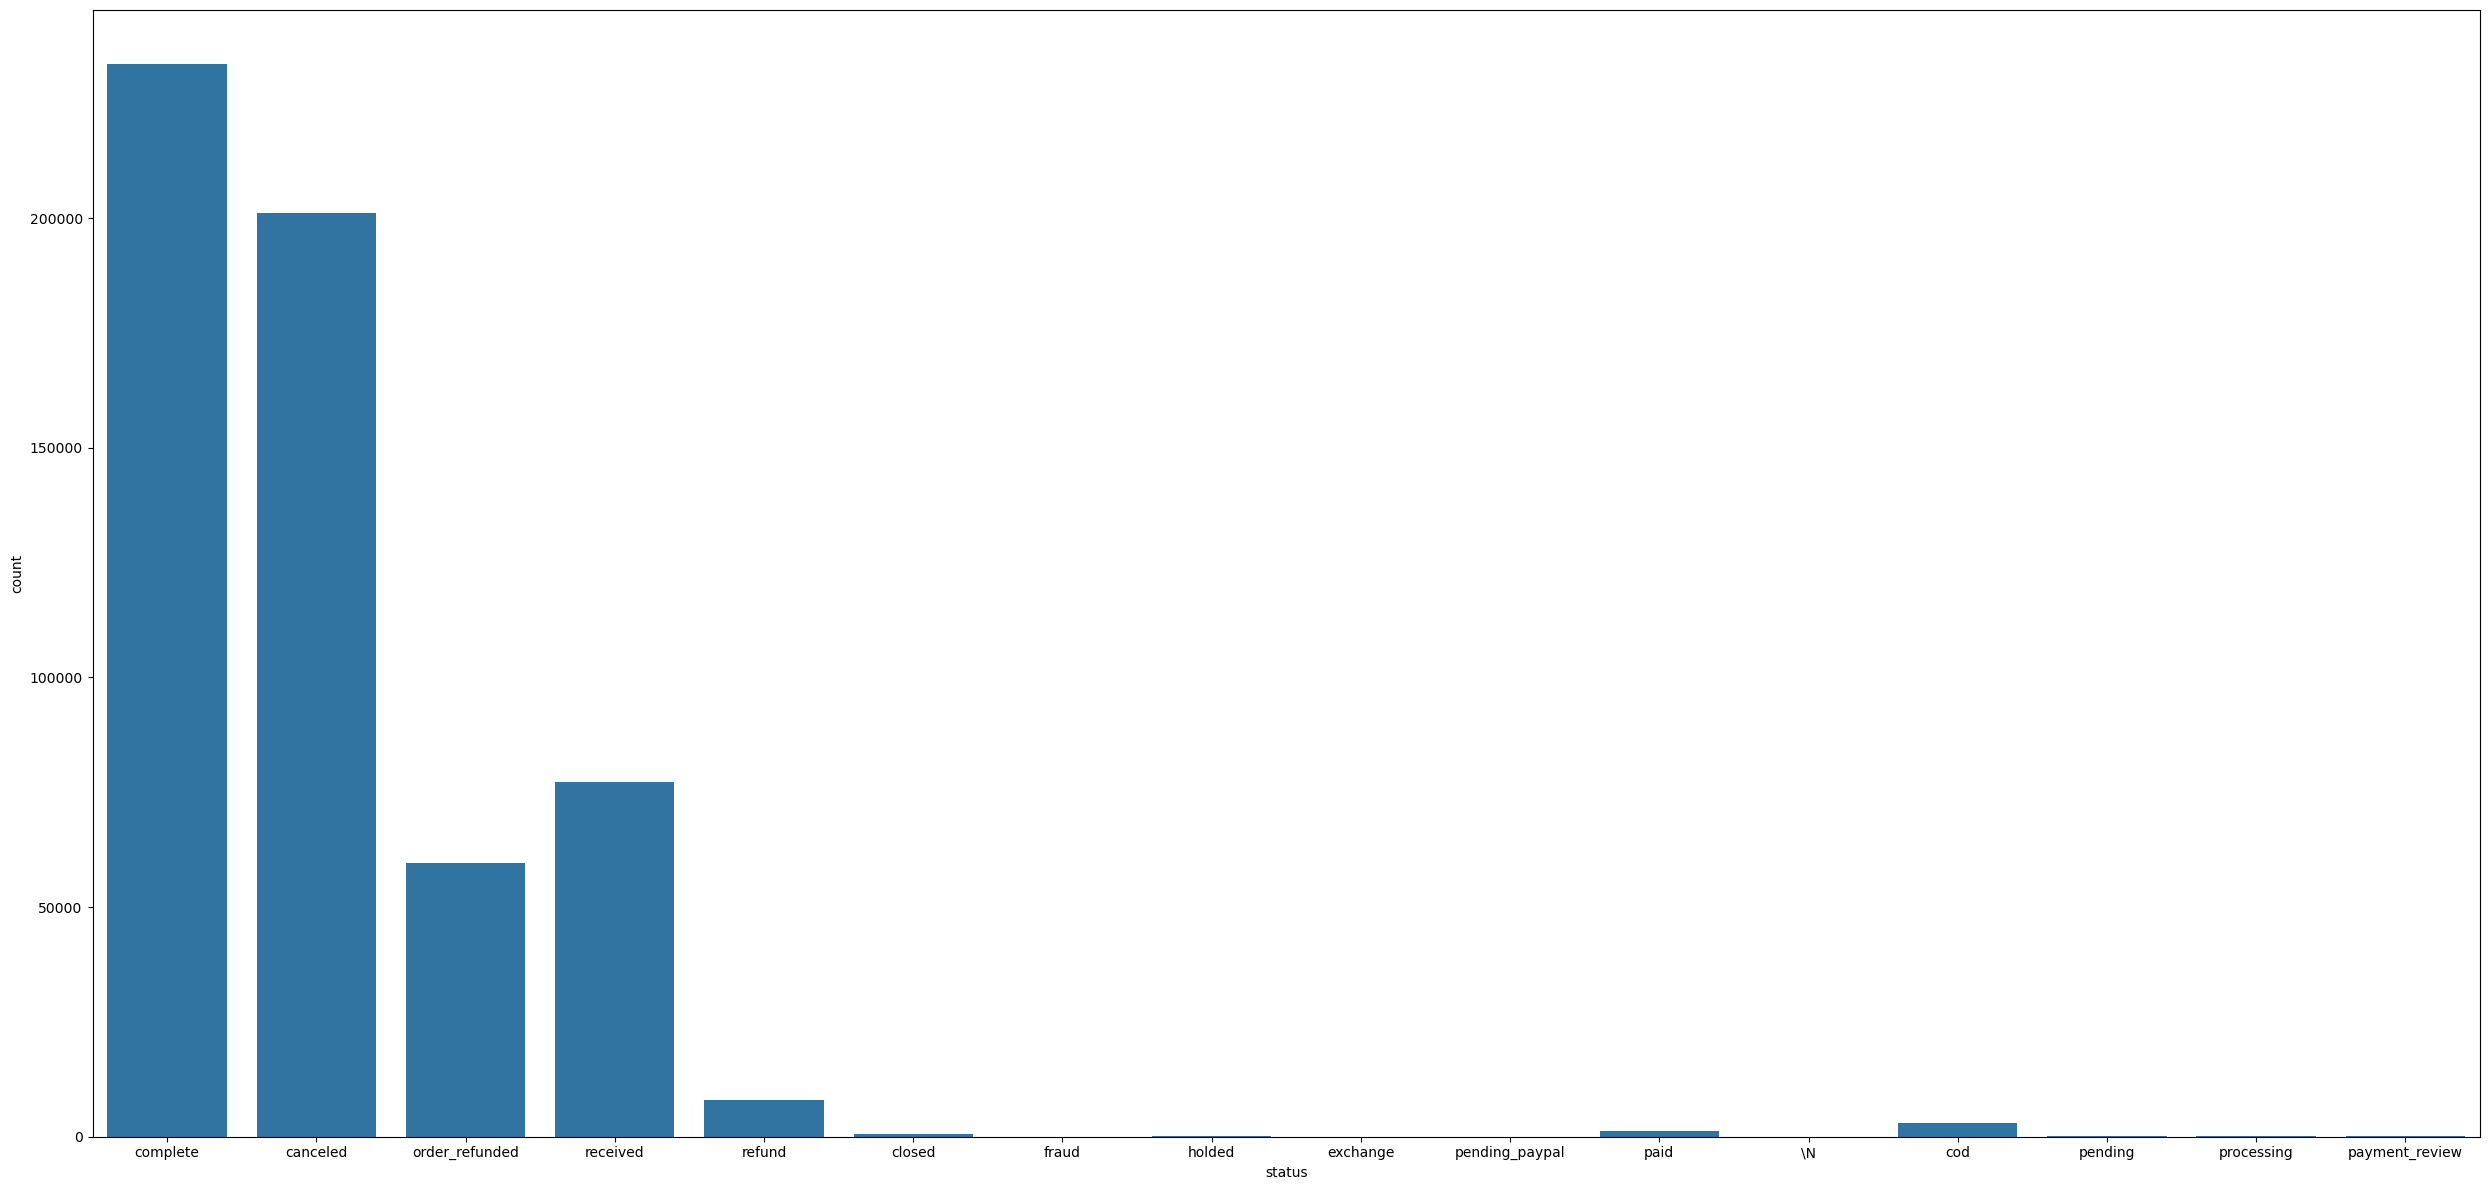

In [51]:
plt.figure(figsize=(25, 12))
sns.countplot(data = df_copy,x = 'status')
plt.tight_layout()
plt.show()

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 26 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   item_id                584524 non-null  float64
 1   status                 584509 non-null  object 
 2   created_at             584524 non-null  object 
 3   sku                    584504 non-null  object 
 4   price                  584524 non-null  float64
 5   qty_ordered            584524 non-null  float64
 6   grand_total            584524 non-null  float64
 7   increment_id           584524 non-null  object 
 8   category_name_1        584360 non-null  object 
 9   sales_commission_code  447346 non-null  object 
 10  discount_amount        584524 non-null  float64
 11  payment_method         584524 non-null  object 
 12  Working Date           584524 non-null  object 
 13  BI Status              584524 non-null  object 
 14   MV                    584524 non-

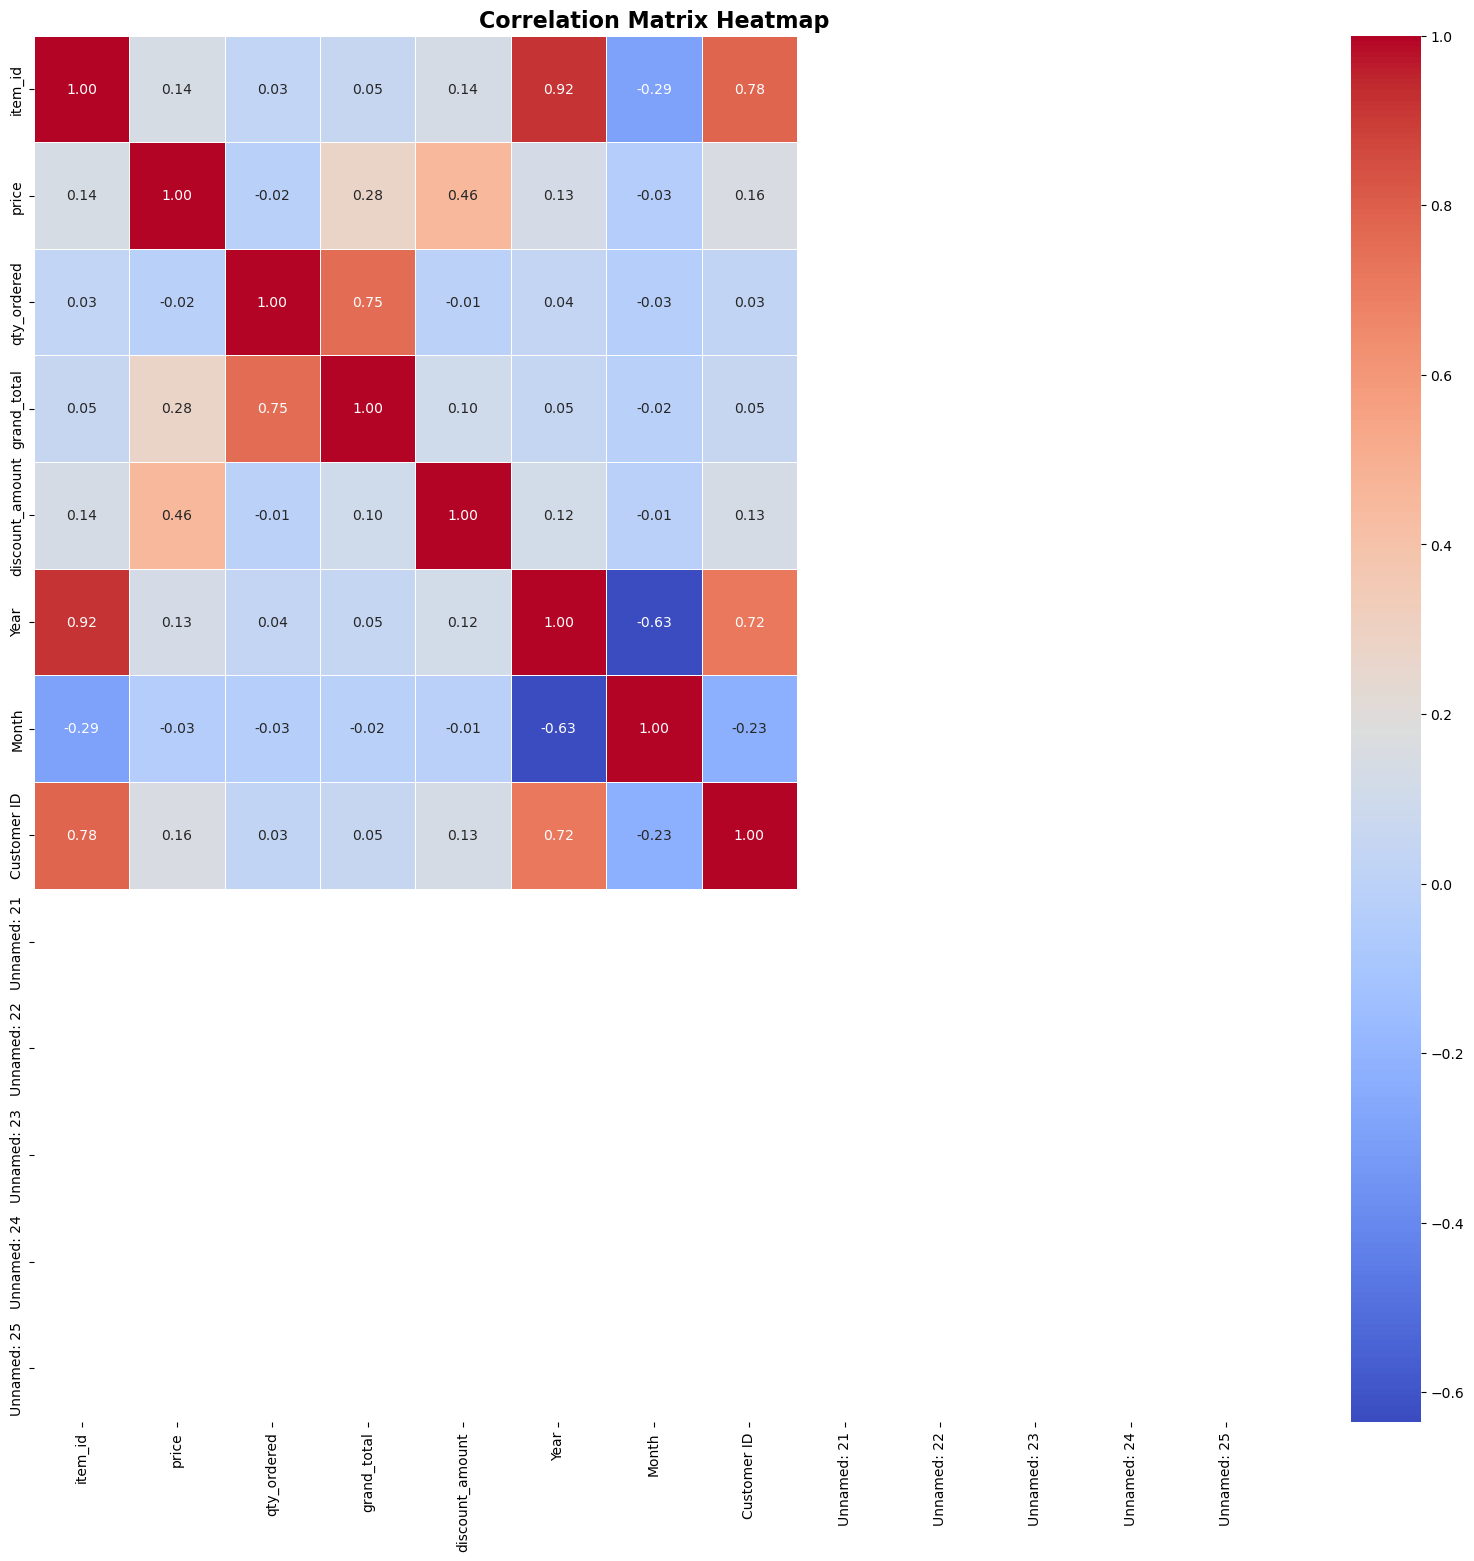

In [66]:
#correlation heat map 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\Hiba\Downloads\archive (3)\Pakistan Largest Ecommerce Dataset.csv",low_memory=False)
numerical_df = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numerical_df.corr()
plt.figure(figsize=(20, 18))  
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap', fontsize=16, fontweight='bold')
plt.show()

In [78]:
#handling missing values in the status column
import pandas as pd
df = pd.read_csv(r"C:\Users\Hiba\Downloads\archive (3)\Pakistan Largest Ecommerce Dataset.csv",low_memory = False)
print(df['status'].isnull().sum())
#dropping the null columns 
df.dropna(subset=['status'], inplace=True)

464066


In [79]:
import pandas as pd
df = pd.read_csv(r"C:\Users\Hiba\Downloads\archive (3)\Pakistan Largest Ecommerce Dataset.csv",low_memory = False)
print(df['status'].unique())
print(df['status'].value_counts())

['complete' 'canceled' 'order_refunded' 'received' 'refund' 'closed'
 'fraud' 'holded' 'exchange' 'pending_paypal' 'paid' '\\N' 'cod' 'pending'
 nan 'processing' 'payment_review']
status
complete          233685
canceled          201249
received           77290
order_refunded     59529
refund              8050
cod                 2859
paid                1159
closed               494
payment_review        57
pending               48
processing            33
holded                31
fraud                 10
pending_paypal         7
exchange               4
\N                     4
Name: count, dtype: int64


In [93]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import tree
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\Hiba\Downloads\archive (3)\Pakistan Largest Ecommerce Dataset.csv", low_memory=False)

# handling missing values by using imputation technique
print(df.isnull().sum())
df.fillna(df.mode().iloc[0], inplace=True) 

#converting categorical values to numerical using label encoder
label_encoder = LabelEncoder()
df['status_encoded'] = label_encoder.fit_transform(df['status'])
print(df[['status', 'status_encoded']].head())
status_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Status to Label Mapping:", status_mapping)

#splitting the dataset into testing and training
X = df.drop(columns=['status'])
y = df['status']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

#performing classification using decision tree algorithm
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
#plotting the tree
plt.figure(figsize=(20, 10))  # Adjust the size of the figure
plot_tree(dt_model, 
          feature_names=X.columns, 
          class_names=label_encoder.classes_,
          filled=True, 
          rounded=True)
plt.title('Decision Tree Visualization')
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Hiba\\Downloads\\archive (3)\\Pakistan Largest Ecommerce Dataset.csv'